<a href="https://colab.research.google.com/github/vitor-thompson/physics-informed-neural-networks-pinn/blob/main/experiments/passo-03-pendulo-nao-linear/passo_03_pendulo_nao_linear.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PINN — Experimento 03: Pêndulo Simples Não-Linear (Grandes Ângulos) com PyTorch

---



## __Tabela de conteúdos__

<ol>
    <li><a href="#Objectives">Objetivos</a></li>
    <li>
        <a href="#Setup">Configuração</a>
        <ol>
            <li><a href="#Installing-Required-Libraries">Instalação das Bibliotecas Necessárias</a></li>
            <li><a href="#Importing-Required-Libraries">Importação das Bibliotecas Necessárias</a></li>
            <li><a href="#Device-Check-for-PyTorch">Verificação de Dispositivo para PyTorch</a></li>
        </ol>
    </li>
    <li>
        <a href="#Background">Contexto Teórico</a>
        <ol>
            <li><a href="#Physics-Informed-Neural-Networks-(PINNs)-Theory">Teoria das Redes Neurais Informadas por Física (PINNs)</a></li>
            <li><a href="#Thermal/Chemical-Diffusion-Theory-&amp;-Numerical-Solution">Pêndulo Simples Não-Linear (Grandes Ângulos)</a></li>
            <li><a href="#Why-PINNs?">Por que PINNs?</a></li>
        </ol>
    </li>
    <li>
        <a href="#The-Model">O Modelo</a>
        <ol>
            <li><a href="#The-Neural-Network">A Rede Neural</a></li>
            <li><a href="#The-Loss-Function">A Função de Perda Física (Loss) e Condições Iniciais</a></li>
            <li><a href="#Training">Treinamento</a></li>
        </ol>
    </li>
    <li>
        <a href="#Result">Resultado</a>
        <ol>
            <li><a href="#Comparing-to-Theoretical-Solution">Comparação com a Solução Teórica</a></li>
            <li><a href="#Visualizing-Training-Convergence">Visualização da Convergência do Treinamento</a></li>
        </ol>
    </li>
</ol>

## 1. Objetivos
Este experimento aplica uma Rede Neural Informada por Física (**PINN**) em PyTorch para resolver a equação diferencial ordinária (EDO) não-linear de 2ª ordem do **Pêndulo Simples Não-Linear (Grandes Ângulos)**. O foco aqui é combinar:
- **Ativação sinusoidal (SIREN)**, adequada para trajetórias oscilatórias e derivadas suaves ao longo do tempo.
- **Condições iniciais exatas por construção (*hard constraints*)** para o ângulo inicial $\theta(0) = \theta_0$ e a velocidade angular inicial $\left.\frac{d\theta}{dt}\right|_{t=0} = \omega_{\text{init}}$.
- **Otimização com L-BFGS** e validação contra uma solução numérica de referência de alta precisão (além do contraste com o regime linearizado de pequenos ângulos).

----


## Configuração

Para este laboratório, você usará as seguintes bibliotecas:

*   [`numpy`](https://numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) para operações matemáticas.
*   [`PyTorch`](https://pytorch.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) para aprendizado de máquina e funções relacionadas a pipelines de deep learning.
*   [`scipy`](https://seaborn.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) para calcular a solução pelo método numérico tradicional.
*   [`matplotlib`](https://matplotlib.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) para ferramentas adicionais de plotagem gráfica.

### Instalação das bibliotecas necessárias

Antes de começarmos a construir nossa Rede Neural Informada por Física (PINN), precisamos garantir que todas as bibliotecas necessárias estejam instaladas. Esta etapa configurará o ambiente necessário para o laboratório, incluindo o `PyTorch` e outros pacotes essenciais.

In [1]:
%pip install torch numpy matplotlib scipy

### Importação das bibliotecas necessárias

_Recomendamos que você importe todas as bibliotecas necessárias em um único lugar (aqui):_

In [2]:
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
from scipy.special import erf

# You can also use this section to suppress warnings generated by your code:
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn
warnings.filterwarnings('ignore')

### Verificação de dispositivo para PyTorch

O `PyTorch` pode ser acelerado por GPU. Se você tiver uma GPU disponível em seu dispositivo local, você pode baixar este notebook e usar a GPU localmente.

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Contexto Teórico

### Teoria das Redes Neurais Informadas por Física (PINNs)

As Redes Neurais Informadas por Física (PINNs) são uma abordagem inovadora que mescla as redes neurais tradicionais com princípios físicos para resolver problemas complexos.

O [Artigo científico sobre PINN](https://www.sciencedirect.com/science/article/abs/pii/S0021999118307125) foi publicado no *Journal of Computational Physics* em 2019.

Diferente das redes neurais convencionais que dependem exclusivamente de dados, **as PINNs incorporam as leis físicas subjacentes, como leis de conservação, condições de contorno e equações diferenciais, diretamente no processo de aprendizado**. Essa integração permite que o modelo seja mais preciso, confiável e interpretável, especialmente quando os dados são escassos ou ruidosos.

Em uma PINN, **a função de perda é aumentada com termos que representam os resíduos das equações diferenciais governantes**. Ao minimizar essa função de perda, a rede neural não apenas se ajusta aos dados, mas também satisfaz as leis físicas. Isso torna as PINNs particularmente poderosas para resolver problemas onde as equações governantes são bem conhecidas, como dinâmica de fluidos, transferência de calor e deformação de materiais.

### 3.2. Pêndulo Simples Não-Linear (Grandes Ângulos)
O **Pêndulo Simples Não-Linear** é descrito por uma equação diferencial ordinária (EDO) de 2ª ordem que modela o movimento angular de uma massa suspensa por um fio inextensível e sem massa, sujeita à gravidade e sem atrito. A equação do movimento é expressa como:

$$mL\frac{d^2\theta(t)}{dt^2} + mg\sin(\theta(t)) = 0 \implies \frac{d^2\theta(t)}{dt^2} + \frac{g}{L}\sin(\theta(t)) = 0$$

com condições iniciais em $t = 0$:

$$\theta(0) = \theta_0, \qquad \left.\frac{d\theta(t)}{dt}\right|_{t=0} = \omega_{\text{init}}$$

Onde:
- $\theta(t)$ é o ângulo de deslocamento em relação à vertical no instante de tempo $t$ (em rad).
- $L$ é o comprimento do pêndulo (em m).
- $g$ é a aceleração da gravidade (em $\text{m/s}^2$).
- $\theta_0$ e $\omega_{\text{init}}$ são, respectivamente, o ângulo inicial e a velocidade angular inicial em $t = 0$.

Diferente do regime de pequenos ângulos ($\sin\theta \approx \theta$), em que o sistema se comporta como um oscilador harmônico linear com frequência angular $\omega_0 = \sqrt{g/L}$, a presença de $\sin(\theta(t))$ para **grandes ângulos** torna a EDO não-linear e faz com que o período de oscilação cresça com a amplitude — sem solução fechada simples em funções elementares. Por isso, comparamos a previsão da PINN com uma **solução numérica de referência de alta precisão** (como `scipy.integrate.solve_ivp` via `RK45`), além de podermos contrastar com a aproximação linear. Enquanto integradores numéricos avançam por passos discretos, a PINN representa $\theta(t)$ como uma função contínua e diferenciável por todo o domínio temporal.

### 3.3. Por que PINNs?
Embora os métodos numéricos tradicionais sejam eficazes para resolver equações diferenciais, eles podem se tornar computacionalmente caros, especialmente para problemas de alta dimensão, geometrias complexas ou sistemas não-lineares. Além disso, esses métodos podem exigir refinamento extensivo de malha, passos de tempo pequenos ou técnicas de estabilização para alcançar soluções precisas.

As Redes Neurais Informadas por Física oferecem uma alternativa poderosa ao incorporar as leis físicas diretamente no processo de treinamento da rede neural. As PINNs podem lidar com problemas que possuem condições de contorno ou iniciais específicas e domínios contínuos sem a necessidade de malhas extensivas ou discretização rígida. Além disso, elas podem ser treinadas sem depender de grandes volumes de dados rotulados, pois a própria equação diferencial guia o aprendizado, garantindo consistência física.

Ao usar PINNs para resolver a equação do **Pêndulo Simples Não-Linear (Grandes Ângulos)**, você ganha intuição prática sobre como embutir uma lei física não-linear diretamente no treinamento da rede neural — e como essa mesma abordagem escala para problemas mais complexos.

Em comparação aos métodos numéricos tradicionais (que dependem de malhas ou passos discretos no tempo), as PINNs se destacam por:
- **Representação contínua e diferenciável:** a rede gera $\theta(t)$ de forma contínua em qualquer instante $t$ dentro do domínio treinado, permitindo avaliar ângulo, velocidade angular ($\frac{d\theta}{dt}$) e aceleração angular ($\frac{d^2\theta}{dt^2}$) via diferenciação automática.
- **Flexibilidade para condições e parâmetros:** a mesma formulação permite testar diferentes condições iniciais ($\theta_0$, $\omega_{\text{init}}$), comprimentos ($L$) ou gravidade ($g$), ou estender o modelo para sistemas com amortecimento, forças externas ou problemas inversos (estimar parâmetros físicos a partir de medições).
- **Base para sistemas mais complexos:** lidar com a não-linearidade do termo $\sin(\theta(t))$ prepara o terreno para pêndulos acoplados (como o pêndulo duplo), dinâmica não-linear mais rica e equações diferenciais parciais (EDPs) em múltiplas dimensões.

### 4.1. A Rede Neural e o *Ansatz* com Condições Iniciais Exatas
Para o **Pêndulo Simples Não-Linear (Grandes Ângulos)**, mantemos a arquitetura **`SirenPINN`** (com ativações senoidais) combinada com **condições iniciais exatas por construção**, incorporando cuidados específicos para lidar com a não-linearidade $\sin(\theta(t))$:

1. **Ativação Senoidal (`SirenPINN`) com Normalização Temporal:** embora o movimento de grandes ângulos não seja uma senoide pura (apresentando harmônicos superiores que alongam o período), ele permanece periódico e suave. Para garantir estabilidade numérica ao avaliar $\sin(\theta(t))$ e suas derivadas de 2ª ordem, normalizamos a entrada temporal para $\tilde{t} \in [-1, 1]$ dentro da rede e aplicamos a inicialização de pesos recomendada para redes SIREN.
2. **Condições Iniciais por Construção (*Hard Constraints*):** definimos a trajetória angular $\theta(t)$ pelo *ansatz*:

$$\theta(t) = \theta_0 + \omega_{\text{init}}\,t + \left(1 - e^{-t^2}\right)\text{NN}(t)$$

Como o fator $\left(1 - e^{-t^2}\right)$ e sua primeira derivada em relação a $t$ anulam-se em $t = 0$, as condições iniciais $\theta(0) = \theta_0$ e $\left.\frac{d\theta}{dt}\right|_{t=0} = \omega_{\text{init}}$ são satisfeitas identicamente desde a primeira época.

In [4]:
# Ativação sinusoidal personalizada para o PyTorch
class SinActivation(nn.Module):

  def forward(self, x):
    return torch.sin(x)


# 1. Rede neural com ativação sinusoidal (SIREN) para trajetórias oscilatórias
class SirenPINN(nn.Module):

  def __init__(self, hidden_dim=64):
    super(SirenPINN, self).__init__()
    self.net = nn.Sequential(
        nn.Linear(1, hidden_dim),
        SinActivation(),
        nn.Linear(hidden_dim, hidden_dim),
        SinActivation(),
        nn.Linear(hidden_dim, hidden_dim),
        SinActivation(),
        nn.Linear(hidden_dim, 1),
    )

  def forward(self, t):
    return self.net(t)


# 2. Ansatz que satisfaz as condições iniciais por construção (Hard constraints)
# theta(t) = theta_0 + omega_init * t + (1 - e^(-t^2)) * NN(t)
def get_exact_pendulum_prediction(model, t, theta_0, omega_init):
  nn_out = model(t)
  factor = 1.0 - torch.exp(-(t**2))
  return theta_0 + omega_init * t + factor * nn_out

### 4.2. A Função de Perda Física (Loss) e Condições Iniciais
Como o *ansatz* `get_exact_pendulum_prediction` já impõe $\theta(0) = \theta_0$ e $\left.\frac{d\theta}{dt}\right|_{t=0} = \omega_{\text{init}}$ por construção, não precisamos somar parcelas extras de erro para as condições iniciais.

A função `exact_ic_pendulum_loss` avalia $\theta_{\text{pred}}(t)$ em pontos de colocação $t_{\text{colloc}}$, calcula as derivadas $\frac{d\theta}{dt}$ e $\frac{d^2\theta}{dt^2}$ com `torch.autograd.grad` (`create_graph=True`) e minimiza apenas o erro quadrático médio do resíduo da EDO não-linear:

$$r(t) = \frac{d^2\theta}{dt^2} + \frac{g}{L}\sin(\theta(t))$$

Assim, toda a capacidade do otimizador fica concentrada em fazer a trajetória angular satisfazer a dinâmica não-linear do pêndulo em todo o intervalo de tempo.

In [5]:
def exact_ic_pendulum_loss(model, t_colloc, g, L, theta_0, omega_init):
  # Garante que t_colloc permita calcular derivadas via autograd
  t = t_colloc.detach().clone().requires_grad_(True)

  # 1. Calcula theta(t) respeitando as condições iniciais por construção
  theta_pred = get_exact_pendulum_prediction(model, t, theta_0, omega_init)

  # 2. Primeira derivada: d(theta)/dt (velocidade angular)
  dtheta_dt = torch.autograd.grad(
      outputs=theta_pred,
      inputs=t,
      grad_outputs=torch.ones_like(theta_pred),
      create_graph=True,
      retain_graph=True,
  )[0]

  # 3. Segunda derivada: d^2(theta)/dt^2 (aceleração angular)
  d2theta_dt2 = torch.autograd.grad(
      outputs=dtheta_dt,
      inputs=t,
      grad_outputs=torch.ones_like(dtheta_dt),
      create_graph=True,
      retain_graph=True,
  )[0]

  # 4. Resíduo da EDO não-linear: d^2(theta)/dt^2 + (g / L) * sin(theta) = 0
  residual = d2theta_dt2 + (g / L) * torch.sin(theta_pred)

  # 5. Média dos quadrados do resíduo (MSE)
  loss = torch.mean(residual**2)
  return loss

### 4.3. Treinamento com L-BFGS e Condições Iniciais Exatas
Neste treinamento, reinicializamos o modelo com `SirenPINN()` e utilizamos o otimizador **L-BFGS** (`line_search_fn="strong_wolfe"`), que faz ajustes quasi-Newton (de segunda ordem) muito precisos em problemas suaves de física.

A cada iteração (em `300` passos externos com `max_iter=50` internos), sorteamos novos pontos de colocação aleatórios `t_colloc` (`N_colloc = 1000`) em $[0, t_{\max}]$ e definimos a função `closure()` exigida pelo **L-BFGS** para zerar gradientes, calcular a perda do resíduo não-linear (`exact_ic_pendulum_loss`), retropropagar o erro e ajustar os pesos de modo que $\theta(t)$ obedeça à EDO do pêndulo ao longo de todo o intervalo.

In [6]:
def train_pendulum(
    model,
    optimizer,
    epochs=300,
    t_max=10.0,
    g=9.81,
    L=2.45,
    theta_0=1.5,
    omega_init=0.0,
    n_colloc=1000,
):
  saved_models = {}
  epoch_saved = []
  loss_history = []

  for epoch in tqdm(range(epochs), desc="Training Pendulum (Hard ICs)"):
    # Amostragem dinâmica de pontos de colocação no intervalo [0, t_max]
    t_colloc = (torch.rand((n_colloc, 1), device=device) * t_max).requires_grad_(
        True
    )

    last_loss = None

    def closure():
      nonlocal last_loss
      optimizer.zero_grad()
      loss = exact_ic_pendulum_loss(
          model=model,
          t_colloc=t_colloc,
          g=g,
          L=L,
          theta_0=theta_0,
          omega_init=omega_init,
      )
      loss.backward()
      last_loss = loss.item()
      return loss

    optimizer.step(closure)

    loss_history.append(last_loss)
    saved_models[epoch + 1] = {
        param_name: tensor.cpu().clone()
        for param_name, tensor in model.state_dict().items()
    }
    epoch_saved.append(epoch + 1)

  return model, epoch_saved, saved_models, loss_history

Você pode configurar e treinar o modelo ajustando o número de passos externos (por exemplo, `10` iterações com `max_iter=50` no `L-BFGS`, ou mais iterações conforme o comprimento $L$, a gravidade $g$, a amplitude inicial $\theta_0$ e o intervalo de tempo escolhido), monitorando a perda ao longo do processo. Se você tiver uma GPU disponível no Colab ou localmente, o treinamento tende a rodar mais rápido e permite testar mais iterações para refinar a convergência.

Esse processo permite que a PINN aprenda uma solução que respeita a equação do movimento não-linear do pêndulo e as duas condições iniciais (ângulo inicial $\theta_0$ e velocidade angular inicial $\omega_{\text{init}}$ em $t = 0$, impostas por construção no *ansatz*) sem depender de uma grande base de dados rotulados.

In [31]:
# Parâmetros físicos do pêndulo simples não-linear (sem atrito)
g = 9.81  # aceleração da gravidade (m/s^2)
L = 2.4525  # comprimento do fio (m) -> g / L ≈ 4.0 s^-2
theta_0 = 1.5  # ângulo inicial em t = 0 (rad)
omega_init = 0.0  # velocidade angular inicial em t = 0 (rad/s)
t_max = 10.0  # intervalo de tempo [0, t_max] (s)

# Reinicializa o modelo
model = SirenPINN().to(device)

# Otimizador L-BFGS com taxa de aprendizado reduzida para 0.01 para estabilidade numérica
optimizer_lbfgs = optim.LBFGS(
    model.parameters(), lr=0.01, max_iter=50, line_search_fn="strong_wolfe"
)

print(
    "Treinando a PINN para o pêndulo não-linear com condições iniciais"
    " exatas..."
)

saved_models = {}
epoch_saved = []
loss_history = []

# Altere o número dentro de range() para definir a quantidade de épocas de treinamento desejada
NUM_EPOCHS = 100

for epoch in tqdm(range(NUM_EPOCHS), desc="Training Pendulum (Hard ICs)"):
  # Pontos de colocação dinâmicos
  N_colloc = 1000
  t_colloc = (torch.rand((N_colloc, 1), device=device) * t_max).requires_grad_(
      True
  )

  last_loss = None

  def closure():
    global last_loss
    optimizer_lbfgs.zero_grad()
    loss = exact_ic_pendulum_loss(model, t_colloc, g, L, theta_0, omega_init)
    loss.backward()
    last_loss = loss.item()
    return loss

  optimizer_lbfgs.step(closure)

  loss_history.append(last_loss)
  saved_models[epoch + 1] = {
      param_name: tensor.cpu().clone()
      for param_name, tensor in model.state_dict().items()
  }
  epoch_saved.append(epoch + 1)

Treinando a PINN para o pêndulo não-linear com condições iniciais exatas...


Training Pendulum (Hard ICs): 100%|██████████| 100/100 [00:55<00:00,  1.79it/s]


## Resultado

### Comparação com a Solução Teórica

### 5.1. Comparação com a Solução de Referência (Hard ICs + SIREN)
Com o modelo treinado, avaliamos a previsão gerada por `get_exact_pendulum_prediction` em uma malha de `300` pontos no intervalo $[0, t_{\max}]$ e comparamos diretamente com uma **solução numérica de referência de alta precisão** (obtida via `scipy.integrate.solve_ivp` com método `RK45`), além de podermos contrastar com a aproximação linear de pequenos ângulos ($\sin\theta \approx \theta$):

$$\frac{d^2\theta}{dt^2} + \frac{g}{L}\sin(\theta(t)) = 0, \qquad \theta(0) = \theta_0, \qquad \left.\frac{d\theta}{dt}\right|_{t=0} = \omega_{\text{init}}$$

destacando o ponto inicial exato em $t = 0$ ($\theta(0) = \theta_0$) e o efeito da não-linearidade sobre o período de oscilação ao longo do tempo.

In [32]:
from scipy.integrate import solve_ivp

def plot_pendulum_solutions(
    model,
    t_max=10.0,
    g=9.81,
    L=2.4525,
    theta_0=1.5,
    omega_init=0.0,
    show_linear_approx=True,
):
  # Pontos no tempo para visualização contínua (300 pontos)
  t_plot_np = np.linspace(0.0, t_max, 300)
  t_plot_tensor = torch.tensor(
      t_plot_np, dtype=torch.float32, device=device
  ).unsqueeze(1)

  # 1. Solução numérica de referência (EDO não-linear: d^2(theta)/dt^2 + (g/L)*sin(theta) = 0)
  def pendulum_ode(t, y):
    theta, omega = y
    dtheta_dt = omega
    domega_dt = -(g / L) * np.sin(theta)
    return [dtheta_dt, domega_dt]

  sol_ref = solve_ivp(
      fun=pendulum_ode,
      t_span=(0.0, t_max),
      y0=[theta_0, omega_init],
      t_eval=t_plot_np,
      method="RK45",
      rtol=1e-10,
      atol=1e-12,
  )
  theta_ref = sol_ref.y[0]

  # 2. Aproximação linear de pequenos ângulos (opcional, para comparação)
  omega_linear = np.sqrt(g / L)
  theta_linear = theta_0 * np.cos(omega_linear * t_plot_np) + (
      omega_init / omega_linear
  ) * np.sin(omega_linear * t_plot_np)

  # 3. Previsão contínua da PINN com condições iniciais exatas
  model.eval()
  with torch.no_grad():
    theta_pinn_pred = (
        get_exact_pendulum_prediction(model, t_plot_tensor, theta_0, omega_init)
        .cpu()
        .numpy()
        .squeeze()
    )

  # Gráfico comparativo contínuo
  plt.figure(figsize=(10, 5), dpi=100)
  plt.plot(
      t_plot_np,
      theta_ref,
      "tab:blue",
      linewidth=2.5,
      label="Referência Numérica (RK45 — Pêndulo Não-Linear)",
  )
  if show_linear_approx:
    plt.plot(
        t_plot_np,
        theta_linear,
        "tab:green",
        linestyle=":",
        linewidth=1.8,
        alpha=0.85,
        label="Aproximação Linear (sin(θ) ≈ θ)",
    )
  plt.plot(
      t_plot_np,
      theta_pinn_pred,
      "tab:orange",
      linestyle="--",
      linewidth=2.0,
      label="PINN (Previsão contínua)",
  )

  # Instantes específicos para comparação discreta
  sampled_times_np = np.linspace(0.0, t_max, 5)
  sampled_times_tensor = torch.tensor(
      sampled_times_np, dtype=torch.float32, device=device
  ).unsqueeze(1)

  sol_sampled = solve_ivp(
      fun=pendulum_ode,
      t_span=(0.0, t_max),
      y0=[theta_0, omega_init],
      t_eval=sampled_times_np,
      method="RK45",
      rtol=1e-10,
      atol=1e-12,
  )
  theta_sampled_ref = sol_sampled.y[0]

  with torch.no_grad():
    theta_sampled_pinn = (
        get_exact_pendulum_prediction(
            model, sampled_times_tensor, theta_0, omega_init
        )
        .cpu()
        .numpy()
        .squeeze()
    )

  plt.scatter(
      0.0,
      theta_0,
      color="black",
      s=80,
      zorder=5,
      label=f"Ângulo inicial θ(0) = {theta_0:.2f} rad",
  )
  plt.scatter(
      sampled_times_np,
      theta_sampled_ref,
      color="tab:blue",
      marker="o",
      s=50,
      zorder=4,
      label="Valores de referência nos instantes",
  )
  plt.scatter(
      sampled_times_np,
      theta_sampled_pinn,
      color="tab:orange",
      marker="x",
      s=60,
      zorder=4,
      label="Valores PINN nos instantes",
  )

  plt.title(
      "PINN vs. Referência Numérica — Pêndulo Simples Não-Linear (Sem Atrito)"
  )
  plt.xlabel("Tempo $t$ (s)")
  plt.ylabel("Ângulo $\\theta(t)$ (rad)")
  plt.grid(True, alpha=0.3)
  plt.legend(loc="lower right")
  plt.tight_layout()
  plt.show()

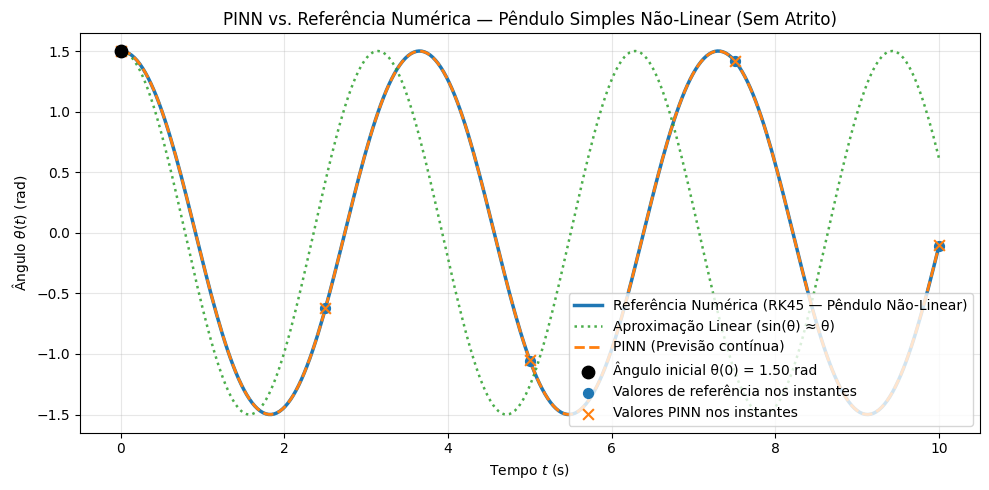

In [33]:
# 1. Plotamos o resultado comparativo atualizado
plot_pendulum_solutions(
    model=model,
    t_max=t_max,
    g=g,
    L=L,
    theta_0=theta_0,
    omega_init=omega_init,
    show_linear_approx=True,
)

Podemos ver que, apesar de pequenas diferenças, a PINN modelou com sucesso o **pêndulo simples não-linear** ao longo do tempo, acompanhando bem tanto as condições iniciais de ângulo ($\theta_0$) e velocidade angular ($\omega_{\text{init}}$) em $t = 0$ quanto a oscilação periódica contínua sem perda artificial de amplitude ou amortecimento ao longo do intervalo — capturando inclusive o desvio em relação à aproximação linear para grandes ângulos.

### Visualização da Convergência do Treinamento

### 5.2. Visualização da Convergência do Treinamento
Vamos visualizar como a previsão da PINN converge ao longo das épocas de treinamento, usando $t = 1{,}0\text{ s}$ (ou outro instante dentro de $[0, t_{\max}]$) como ponto de acompanhamento. Isso permite observar como a rede refina sua estimativa angular $\theta(t)$ e se aproxima do valor de referência numérico $\theta_{\text{ref}}(1{,}0)$ (calculado via `solve_ivp`) à medida que o treinamento avança.

In [34]:
from matplotlib import animation
from scipy.integrate import solve_ivp


def plot_pendulum_epoch_comparison(
    epoch_saved,
    saved_models,
    device,
    t_max=10.0,
    g=9.81,
    L=2.4525,
    theta_0=1.5,
    omega_init=0.0,
):
  fig, ax = plt.subplots(figsize=(7, 5), dpi=100)

  # Grade temporal para visualizar a curva inteira de theta(t)
  t_np = np.linspace(0.0, t_max, 200)
  t_tensor = torch.tensor(
      t_np, dtype=torch.float32, device=device
  ).unsqueeze(1)

  # Solução numérica de referência: d^2(theta)/dt^2 + (g/L) * sin(theta) = 0
  def pendulum_ode(t, y):
    theta, omega = y
    return [omega, -(g / L) * np.sin(theta)]

  sol_ref = solve_ivp(
      fun=pendulum_ode,
      t_span=(0.0, t_max),
      y0=[theta_0, omega_init],
      t_eval=t_np,
      method="RK45",
      rtol=1e-10,
      atol=1e-12,
  )
  theta_ref = sol_ref.y[0]

  ax.plot(
      t_np,
      theta_ref,
      "k--",
      linewidth=2,
      label="Referência Numérica (RK45 — Pêndulo Não-Linear)",
  )
  (line,) = ax.plot([], [], "r-", linewidth=2, label="PINN Solution")

  # Estimativa da amplitude máxima angular via conservação de energia mecânica:
  # (1/2) * omega^2 - (g/L) * cos(theta) = const
  energy_const = 0.5 * (omega_init**2) - (g / L) * np.cos(theta_0)
  cos_theta_min = max(-1.0, min(1.0, -(energy_const / (g / L))))
  amp_max = max(abs(theta_0), np.arccos(cos_theta_min))
  y_margin = max(0.25 * amp_max, 0.2)

  ax.set_xlim(0.0, t_max)
  ax.set_ylim(-(amp_max + y_margin), amp_max + y_margin)

  ax.set_title("PINN vs. Referência Numérica ao Longo das Épocas")
  ax.set_xlabel("Tempo $t$ (s)")
  ax.set_ylabel("Ângulo $\\theta(t)$ (rad)")
  ax.legend()
  ax.grid(True, alpha=0.3)

  temp_model = SirenPINN().to(device)
  temp_model.eval()

  def init():
    line.set_data([], [])
    return (line,)

  def update(epoch):
    temp_model.load_state_dict(
        {param: tensor.to(device) for param, tensor in saved_models[epoch].items()}
    )
    with torch.no_grad():
      theta_pred = (
          get_exact_pendulum_prediction(temp_model, t_tensor, theta_0, omega_init)
          .cpu()
          .numpy()
          .squeeze()
      )
    line.set_data(t_np, theta_pred)
    ax.set_title(f"PINN vs. Referência Numérica — Época {epoch}")
    return (line,)

  ani = animation.FuncAnimation(
      fig,
      update,
      frames=epoch_saved,
      init_func=init,
      blit=False,
      interval=200,
  )

  plt.close(fig)
  return ani


ani = plot_pendulum_epoch_comparison(
    epoch_saved,
    saved_models,
    device,
    t_max=t_max,
    g=g,
    L=L,
    theta_0=theta_0,
    omega_init=omega_init,
)

In [35]:
epoch_show = list(range(1, 1000))
# Mantém apenas as épocas que existem em saved_models (evita KeyError)
epoch_show = [ep for ep in epoch_show if ep in saved_models]

anim = plot_pendulum_epoch_comparison(
    epoch_show,
    saved_models,
    device,
    t_max=t_max,
    g=g,
    L=L,
    theta_0=theta_0,
    omega_init=omega_init,
)

In [36]:
# Usage example
from IPython.display import HTML
HTML(anim.to_jshtml())

## Conclusão
Parabéns!
Neste **Experimento 03**, você aplicou uma Rede Neural Informada por Física (PINN) com ativação sinusoidal (`SirenPINN`), condições iniciais exatas por construção (*hard constraints*) e otimizador **L-BFGS** para resolver a equação diferencial ordinária não-linear de 2ª ordem do **Pêndulo Simples Não-Linear (Grandes Ângulos)** ($\ddot{\theta} + \frac{g}{L}\sin\theta = 0$).

Em vez de depender de grandes volumes de dados rotulados, de penalidades aproximadas para os valores iniciais em $t = 0$ ou da linearização $\sin\theta \approx \theta$, a combinação do *ansatz* com a minimização do resíduo não-linear via `autograd` permitiu acompanhar a oscilação periódica ao longo de todo o intervalo de tempo com alta fidelidade em relação à solução numérica de referência (`solve_ivp` / `RK45`), capturando inclusive os efeitos de grandes amplitudes.

### Próximos passos e aprofundamento
Os princípios vistos aqui — diferenciação automática, imposição de restrições físicas, tratamento de não-linearidades e escolha adequada de ativações e otimizadores — servem de base para problemas mais desafiadores, como:
- **Sistemas físicos mais ricos:** pêndulo amortecido ou forçado, pêndulo duplo e sistemas acoplados com dinâmica não-linear mais complexa ou caos.
- **Modelos de operadores neurais e arquiteturas modernas:** para quem deseja explorar aprendizado de operadores e modelos de sequência em física computacional, vale investigar abordagens como *Fourier Neural Operators* (FNOs), *Graph Neural Networks* (GNNs) e arquiteturas baseadas em *Transformers* aplicadas a equações diferenciais.